# CIS 5800: HW3C — 3D Reconstruction (Fall 2026)

**Student notebook** — run this notebook from the `homework_3/` folder, with `data/` and `code/` as siblings of this file. In Google Colab, first upload and extract the student ZIP into `/content/`, then run `%cd /content/homework_3` before executing notebook cells.

**Correspondence generation is part of this assignment.** The images are provided, but no precomputed keypoints, descriptors, or point correspondences are supplied. Run the SIFT feature detection and matching cells below to generate correspondences, then use them in your implementations of essential-matrix estimation, RANSAC, pose recovery, triangulation, and reprojection.

Only modify the marked `##### STUDENT CODE START #####` sections in `lse.py`, `plot_epi.py`, `pose.py`, `ransac.py`, `recon3d.py`, and `show_reproj.py`. Submit only those six Python files. The notebook and optional interactive visualizer are debugging tools and are not submitted.

See the accompanying HW3 handout for complete instructions.

In [4]:
%matplotlib inline

import matplotlib.pyplot as plt
import cv2
import numpy as np
from pathlib import Path
import sys

# Notebook must run from homework_3/ (also works in Colab after %cd).
assert Path('data/left_30.jpg').is_file() and Path('data/right_30.jpg').is_file(), (
    'Cannot find images. Extract the student ZIP and run this notebook '
    'from the homework_3 directory (in Colab: %cd /content/homework_3).')
Path('result').mkdir(exist_ok=True)
sys.path.insert(0, str(Path('code').resolve()))
np.random.seed(42)
print('OpenCV:', cv2.__version__)
assert hasattr(cv2, 'SIFT_create'), 'OpenCV SIFT is missing; install a recent opencv-python version.'

OpenCV: 5.0.0


## Step 1 — Load the supplied camera images

The images are supplied; **correspondences are not**. The next cells will compute keypoints, descriptors, and matched pixel positions directly from this image pair.

image shape: (720, 1280, 3)


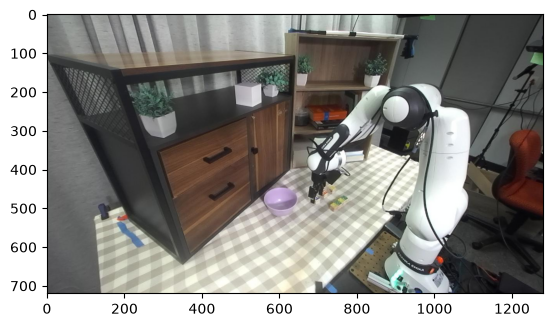

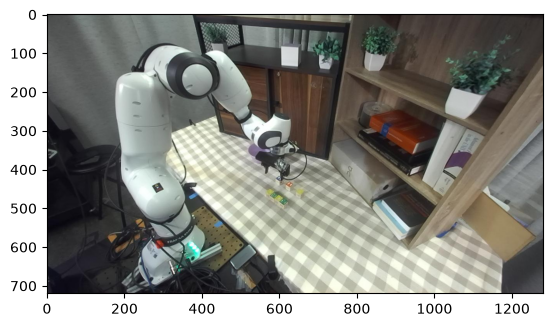

In [5]:
# load the images
im_left = cv2.imread('data/left_30.jpg')
print("image shape:", im_left.shape)
plt.imshow(im_left[:, :, ::-1])
plt.figure()
im_right = cv2.imread('data/right_30.jpg')
plt.imshow(im_right[:, :, ::-1])
images = [im_left, im_right]


In [6]:
# Both provided views are rectified; use zero distortion as specified in the handout.
f1 = f2 = 967.0
u0, v0 = 640.0, 360.0
K = np.array([[f1, 0, u0],
              [0, f2, v0],
              [0, 0, 1]], dtype=float)
print('K =\n', K)

K =
 [[967.   0. 640.]
 [  0. 967. 360.]
 [  0.   0.   1.]]


## Step 2 — Generate correspondences using SIFT

Run the **provided** cells below. They detect SIFT keypoints in both images, compute descriptors, and match them with a brute-force descriptor matcher. You do **not** need to implement SIFT or manually label correspondences. Inspect the matches; some will be outliers, which your RANSAC implementation will remove later.

The resulting matched point arrays are extracted from these matches and calibrated with $K^{-1}$ before the eight-point algorithm.

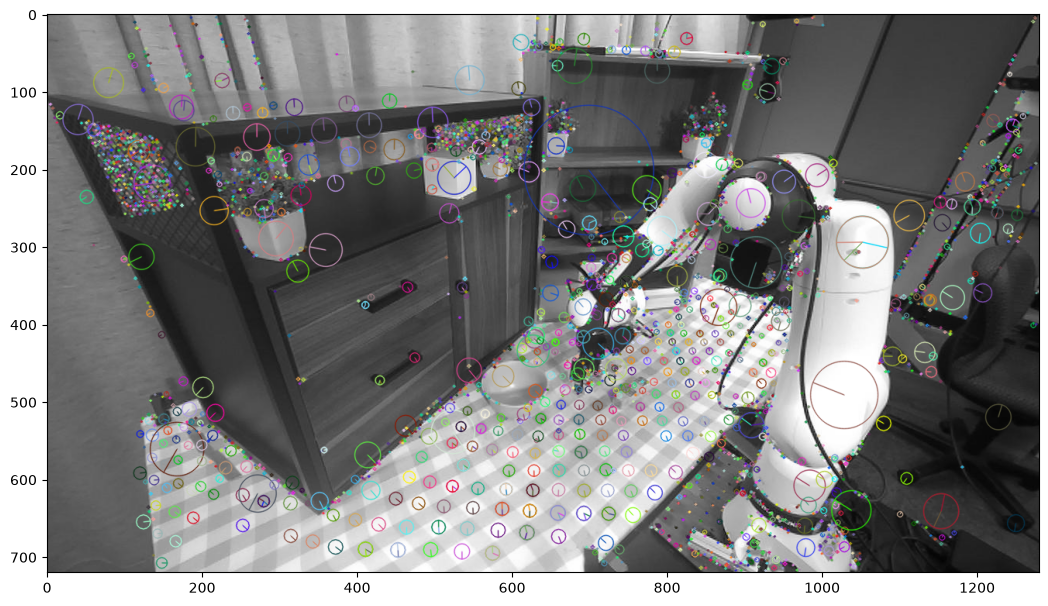

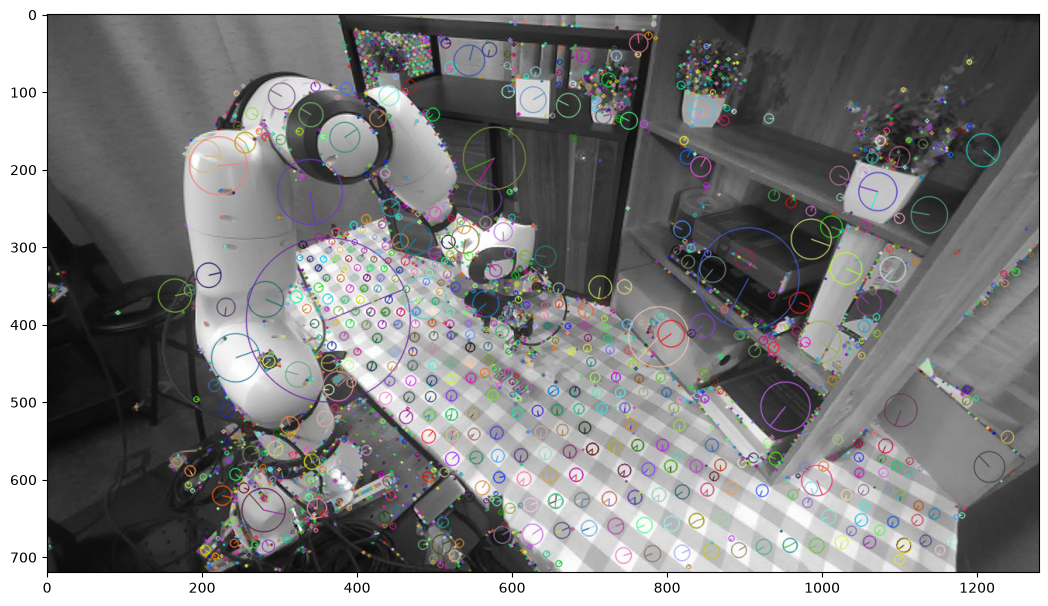

In [7]:
""" Detects SIFT features in all of the images
"""
keypoints = []
descriptions = []
for im in images:
  gray= cv2.cvtColor(im,cv2.COLOR_BGR2GRAY)

  sift = cv2.SIFT_create()
  kp, des = sift.detectAndCompute(gray,None)

  keypoints.append(kp)
  descriptions.append(des)

  plt.figure(figsize=(6.4*2, 4.8*2))
  out_im = cv2.drawKeypoints(gray,kp, gray, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

  plt.imshow(out_im)
  plt.savefig('result/sift_keypoints_{}.png'.format(len(keypoints)), bbox_inches='tight', dpi=150)

num matches 785


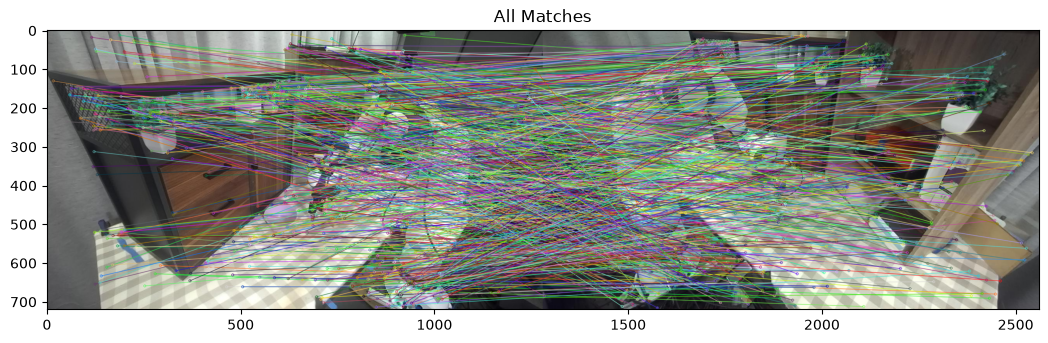

In [8]:
""" Matches the detected keypoints between the images
"""

bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)
matches = bf.match(descriptions[0], descriptions[1])

print("num matches", len(matches))

matched_image = cv2.drawMatches(images[0][:, :, ::-1], keypoints[0], images[1][:, :, ::-1], keypoints[1], matches, None, flags=2)
plt.figure(figsize=(6.4*2, 4.8*2))
plt.title("All Matches")
plt.imshow(matched_image)


In [9]:

""" Compute calibrated coordinates
K is already defined in the calibration cell above.
"""
uncalibrated_1 = [[keypoints[0][match.queryIdx].pt[0], keypoints[0][match.queryIdx].pt[1], 1] for match in matches]
uncalibrated_2 = [[keypoints[1][match.trainIdx].pt[0], keypoints[1][match.trainIdx].pt[1], 1] for match in matches]

uncalibrated_1 = np.array(uncalibrated_1).T
uncalibrated_2 = np.array(uncalibrated_2).T

k_inv = np.linalg.inv(K)

calibrated_1 = np.matmul(k_inv, uncalibrated_1).T
calibrated_2 = np.matmul(k_inv, uncalibrated_2).T

assert len(matches) >= 8, 'Need at least eight correspondences for the eight-point algorithm.'
print('Generated', len(matches), 'raw SIFT correspondences')
print('Pixel points (3xN):', uncalibrated_1.shape, uncalibrated_2.shape)
print('Calibrated points (Nx3):', calibrated_1.shape, calibrated_2.shape)


Generated 785 raw SIFT correspondences
Pixel points (3xN): (3, 785) (3, 785)
Calibrated points (Nx3): (785, 3) (785, 3)


Let's test your `least_squares_estimation` method.

In [10]:
from lse import least_squares_estimation

E_least = least_squares_estimation(calibrated_1, calibrated_2)
print("E least", E_least)

E least [[ 0.61126007  0.3135832  -0.63219194]
 [-0.34132057  0.9328011   0.10421245]
 [ 0.25329697  0.07026164 -0.24856821]]


Let's test your `ransac_estimator` method.

E_ransac [[ 0.00919822  0.82111939  0.26225859]
 [ 0.76383014  0.0575983  -0.60838992]
 [ 0.19512374  0.51173307  0.00790048]]
Num inliers (50,)


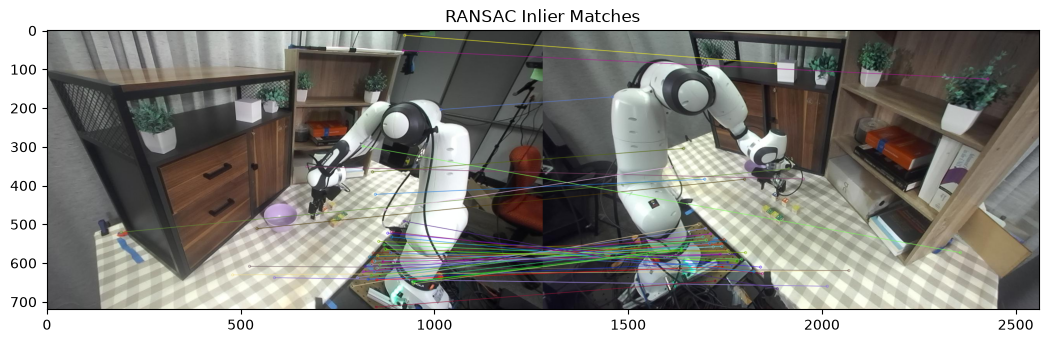

In [11]:
from ransac import ransac_estimator

# running this cell will take a while!!!

E_ransac, inliers = ransac_estimator(calibrated_1, calibrated_2, num_iterations=2000)
# For a longer RANSAC run, increase num_iterations (e.g., to 60000).
print("E_ransac", E_ransac)
print("Num inliers", inliers.shape)

inlier_matches = [matches[i] for i in inliers]

matched_image = cv2.drawMatches(images[0][:, :, ::-1],
                                keypoints[0],
                                images[1][:, :, ::-1],
                                keypoints[1],
                                inlier_matches, None, flags=2)
plt.figure(figsize=(6.4*2, 4.8*2))
plt.title("RANSAC Inlier Matches")
plt.imshow(matched_image)
plt.savefig('result/ransac_inlier_matches.png', bbox_inches='tight', dpi=150)

In [13]:

from plot_epi import plot_epipolar_lines

uncalibrated_inliers_1 = [[keypoints[0][match.queryIdx].pt[0], keypoints[0][match.queryIdx].pt[1], 1] for match in inlier_matches]
uncalibrated_inliers_2 = [[keypoints[1][match.trainIdx].pt[0], keypoints[1][match.trainIdx].pt[1], 1] for match in inlier_matches]
uncalibrated_inliers_1 = np.array(uncalibrated_inliers_1).T
uncalibrated_inliers_2 = np.array(uncalibrated_inliers_2).T

plot_epipolar_lines(images[0], images[1], uncalibrated_inliers_1, uncalibrated_inliers_2, E_ransac, K)
plt.savefig('result/epipolar_lines.png', bbox_inches='tight', dpi=150)


ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 50 is different from 3)

Let's test your `pose_candidates_from_E` method.

In [ ]:
from pose import pose_candidates_from_E

transform_candidates = pose_candidates_from_E(E_ransac)
print("transform_candidates", transform_candidates)
for c in transform_candidates:
  print(np.linalg.det(c['R']))

np.array([[0, -1, 0], [1, 0, 0], [0, 0, 1]]).T

In [ ]:
def plot_reconstruction(P1, P2, T, R):
  P1trans = (R @ P1.T).T + T

  plt.figure(figsize=(6.4*2, 4.8*2))
  ax = plt.axes()
  ax.set_xlabel('x')
  ax.set_ylabel('z')

  for i in range(P1.shape[0]):
    plt.plot([0, P2[i, 0]], [0, P2[i, 2]], 'bs-')
    plt.plot([T[0], P1trans[i, 0]], [T[2], P1trans[i, 2]], 'ro-')
  plt.plot([0], [0], 'bs')
  plt.plot([T[0]], [T[2]], 'ro')
  plt.savefig('result/reconstruction.png', bbox_inches='tight', dpi=150)

Let's test your `reconstruct3D` method.

In [ ]:
from recon3d import reconstruct3D

P1, P2, T, R = reconstruct3D(transform_candidates, calibrated_1[inliers], calibrated_2[inliers])

plot_reconstruction(P1, P2, T, R)

Let's test your `show_reprojections` method. This will display the reprojections on the two images.

In [ ]:
from show_reproj import show_reprojections

show_reprojections(images[0], images[1], uncalibrated_inliers_1, uncalibrated_inliers_2, P1, P2, K, T, R)

## Optional interactive visualizer (local Python environment)

The supplied `code/visualizer.py` generates its own SIFT correspondences from the same two input images. Once you have implemented the six functions, you may use the Gradio visualizer to inspect matches, epipolar lines, reconstructed points, and reprojections.

From the student package directory run:

```bash
cd code
python visualizer.py
```

Open `http://localhost:7860` in your browser. This is optional and is not required for Colab use. It is not part of the submission.